# 포켓몬 GO 연구 · 2단계: 별점별 평가속성 출현 차이 검정

**대상:** 병합 리뷰 2,500건 · 별점 1~5점 · 코딩북 V1.2의 A01~A08

**분석 내용:** 평가속성의 출현 여부(미언급 `9` / 출현 `-1, 0, 1`)를 별점별로 비교하는 5×2 교차분석, Pearson χ², Cramér’s V, 8개 검정의 Benjamini–Hochberg(FDR) 보정, 기대빈도 점검 및 잔차 분석.

> **해석상 주의:** 별점별 균등추출 표본이며, 500건은 사람 A 코딩, 나머지 2,000건은 이전 작업의 AI 예비 판정 기반 자료일 수 있습니다. 아래 유의확률은 코딩의 타당성을 검증하지 않으며, 모든 결과는 해당 라벨의 정확성을 전제로 합니다.

## 1. 환경 설정과 입력 파일

필요 패키지: `pandas`, `numpy`, `scipy`, `matplotlib`, `IPython`.

파일명만 맞추면 같은 폴더에서 실행할 수 있습니다. `INPUT_FILE`에 절대경로를 지정해도 됩니다.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, random_table
from IPython.display import display

INPUT_FILE = Path('PokemonGO_Merged_2500_V1_2.csv')
if not INPUT_FILE.exists():
    # 예: 작업 폴더를 변경한 사용자를 위한 명시적 대체 경로
    candidate = Path('/mnt/data') / INPUT_FILE.name
    if candidate.exists():
        INPUT_FILE = candidate
    else:
        raise FileNotFoundError(f'최신 병합 CSV를 찾을 수 없습니다: {INPUT_FILE.resolve()}')

OUT_DIR = Path('PokemonGO_Stage2_Results')
OUT_DIR.mkdir(parents=True, exist_ok=True)

ASPECTS = {
 'A01':'게임 콘텐츠·플레이 경험',
 'A02':'과금·게임 내 경제',
 'A03':'보상·확률·성취',
 'A04':'기술적 안정성·이용 편의성',
 'A05':'공간적 접근성·지역 격차',
 'A06':'사회적 상호작용·협력',
 'A07':'게임 운영·서비스 관리',
 'A08':'기기·자원 부담·호환성',
}
RATINGS = [1,2,3,4,5]
VALID_CODES = {-1,0,1,9}
MONTE_CARLO_REPETITIONS = 10000
RANDOM_SEED = 20261106
ALPHA = 0.05
print('입력 파일:', INPUT_FILE.resolve())
print('출력 폴더:', OUT_DIR.resolve())

입력 파일: D:\vscode_project\포켓몬고\PokemonGO_Merged_2500_V1_2.csv
출력 폴더: D:\vscode_project\포켓몬고\PokemonGO_Stage2_Results


## 2. 데이터 무결성 검증

`U`, 결측값, 혼합 감성 `8`, 범위 밖 별점 등이 남아 있으면 **분석을 중단**합니다. `9`는 미출현이며 중립 `0`은 **출현**으로 처리합니다.

In [3]:
df = pd.read_csv(INPUT_FILE, encoding='utf-8-sig', low_memory=False)
required = ['ID', '별점_숫자'] + list(ASPECTS)
missing_columns = [col for col in required if col not in df.columns]
if missing_columns:
    raise ValueError(f'필수 열이 없습니다: {missing_columns}')
if df['ID'].isna().any() or df['ID'].astype(str).str.strip().eq('').any():
    raise ValueError('ID 결측/공백이 있습니다.')
if df['ID'].duplicated().any():
    raise ValueError(f'ID 중복: {df["ID"].duplicated().sum()}건')

rating = pd.to_numeric(df['별점_숫자'], errors='coerce')
if rating.isna().any() or not rating.isin(RATINGS).all():
    raise ValueError('별점은 1~5의 정수여야 합니다.')
df['별점_숫자'] = rating.astype(int)
for col in ASPECTS:
    values = pd.to_numeric(df[col], errors='coerce')
    invalid = values.isna() | ~values.isin(VALID_CODES)
    if invalid.any():
        examples = df.loc[invalid, ['ID',col]].head(5).to_dict('records')
        raise ValueError(f'{col}: 잘못된 코딩값 {invalid.sum()}개 (U 포함 여부 확인). 예: {examples}')
    df[col] = values.astype(int)

rating_n = df['별점_숫자'].value_counts().reindex(RATINGS, fill_value=0)
if (rating_n == 0).any():
    raise ValueError('어느 한 별점에 리뷰가 없습니다. 5×2 분석이 불가능합니다.')
assert len(df) == 2500, f'예상 2500건과 다릅니다: {len(df)}건'
print('검증 통과:',len(df),'건 / 중복 ID 0 / 코딩값 이상 없음')
display(rating_n.rename('표본 수').to_frame())
if '자료구분' in df.columns:
    print('자료구분:', df['자료구분'].value_counts().to_dict())

검증 통과: 2500 건 / 중복 ID 0 / 코딩값 이상 없음


,표본 수
별점_숫자,
1,500
2,500
3,500
4,500
5,500


자료구분: {'본분석_2000': 2000, '사람A_500': 500}


## 3. 분석 함수

- **Pearson χ²:** 별점과 평가속성 출현의 독립성 검정(자유도=4).
- **Cramér’s V:** 두 변수의 관련 강도(5×2표이므로 `sqrt(χ²/n)`).
- **기대빈도:** 모든 셀의 기대빈도가 5 이상이면 근사 χ² 검정 해석이 비교적 안정적입니다.
- **조건부 몬테카를로:** 기대빈도가 5 미만인 셀이 존재하면 행·열 주변합을 고정한 무작위 표본에서 χ² 통계량의 꼬리 확률을 추정합니다(재현 가능한 시드, 유한 반복에 따른 오차 존재).
- **다중검정:** 8개 평가속성의 주 검정 p값에 BH-FDR 보정을 적용합니다.

※ Cramér’s V의 관례적 크기 기준은 5×2 표의 해석 맥락에 따라 달라지므로 기계적으로 효과크기를 ‘작음·중간·큼’으로 단정하지 않습니다.

In [4]:
def bh_fdr(p_values):
    """Benjamini-Hochberg adjusted p values, original order."""
    arr=np.asarray(p_values,dtype=float)
    if not np.isfinite(arr).all() or (arr<0).any() or (arr>1).any():
        raise ValueError('p값에 유효하지 않은 값이 있습니다.')
    m=len(arr); order=np.argsort(arr); sorted_p=arr[order]
    adjusted=np.minimum.accumulate((sorted_p*m/np.arange(1,m+1))[::-1])[::-1]
    out=np.empty(m,dtype=float); out[order]=np.minimum(adjusted,1.0)
    return out

def conditional_mc_pvalue(table, observed_chi2, reps=10000, seed=20261106):
    """고정 주변합의 5x2 random tables; +1 보정의 Monte Carlo p."""
    row_sums=table.sum(axis=1).astype(int)
    col_sums=table.sum(axis=0).astype(int)
    expected=np.outer(row_sums,col_sums)/table.sum()
    rng=np.random.default_rng(seed)
    extreme=0
    # 배치 처리로 메모리 사용량 제한
    for start in range(0,reps,1000):
        size=min(1000,reps-start)
        sims=random_table.rvs(row_sums,col_sums,size=size,random_state=rng)
        sims=np.asarray(sims).reshape(size,*table.shape)
        sim_chisq=((sims-expected)**2/expected).sum(axis=(1,2))
        extreme+=np.count_nonzero(sim_chisq >= observed_chi2-1e-12)
    return (extreme+1)/(reps+1)

# BH-FDR 구현의 간단한 검증
assert np.allclose(bh_fdr([.01,.04,.03]), [.03,.04,.04])

## 4. 평가속성별 카이제곱 검정 · 효과크기 · 잔차

모든 평가속성에서 **출현=1, 미출현=0**을 만들고 별점별 5×2표를 계산합니다. 결과 표는 별점별 출현율과 출현/미출현 건수도 함께 저장합니다.

In [5]:
results=[]; count_records=[]; residual_records=[]; contingency_tables={}
for idx,(aspect,name) in enumerate(ASPECTS.items()):
    present=df[aspect].ne(9).astype(int)
    table=pd.crosstab(df['별점_숫자'],present).reindex(index=RATINGS, columns=[0,1],fill_value=0)
    table.columns=['미출현','출현']
    observed=table.to_numpy(dtype=int)
    contingency_tables[aspect]=table
    # 두 결과(출현/미출현)가 모두 있어야 5x2 독립성 검정 정의 가능
    if (observed.sum(axis=0)==0).any():
        raise ValueError(f'{aspect}: 모든 리뷰가 출현 또는 미출현으로 같아서 카이제곱 검정을 계산할 수 없습니다.')
    chi2,p_pearson,dof,expected=chi2_contingency(observed,correction=False)
    cramer_v=float(np.sqrt(chi2/(observed.sum()*min(observed.shape[0]-1,observed.shape[1]-1))))
    small_expected=int(np.count_nonzero(expected<5))
    mc_p=(conditional_mc_pvalue(observed,chi2,MONTE_CARLO_REPETITIONS,RANDOM_SEED+idx)
          if small_expected>0 else np.nan)
    p_primary=float(mc_p if small_expected>0 else p_pearson)
    results.append({
        '코드':aspect,'평가속성':name,'N':int(observed.sum()),
        '출현건수':int(observed[:,1].sum()), '출현율(%)':round(observed[:,1].sum()/observed.sum()*100,2),
        'χ²':float(chi2),'자유도':int(dof), 'Pearson_p':float(p_pearson),
        '최소기대빈도':float(expected.min()),'기대빈도5미만셀':small_expected,
        '조건부_MC_p':mc_p,'주검정방식':'조건부 몬테카를로' if small_expected>0 else 'Pearson χ²',
        '주검정_p':p_primary,'Cramér_V':cramer_v,
    })
    for i,star in enumerate(RATINGS):
        count_records.append({'코드':aspect,'평가속성':name,'별점':star,'전체건수':int(observed[i].sum()),
                              '출현건수':int(observed[i,1]),'미출현건수':int(observed[i,0]),
                              '출현율(%)':round(observed[i,1]/observed[i].sum()*100,2)})
        # 조정 표준화잔차: (O-E)/sqrt(E*(1-row proportion)*(1-col proportion))
        row_frac=observed[i].sum()/observed.sum()
        for j,category in enumerate(['미출현','출현']):
            col_frac=observed[:,j].sum()/observed.sum()
            std_resid=(observed[i,j]-expected[i,j])/np.sqrt(expected[i,j]*(1-row_frac)*(1-col_frac))
            residual_records.append({'코드':aspect,'별점':star,'구분':category,
                                      '관측빈도':int(observed[i,j]),'기대빈도':expected[i,j],
                                      '조정표준화잔차':float(std_resid)})

summary=pd.DataFrame(results)
summary['BH_FDR_q']=bh_fdr(summary['주검정_p'].to_numpy())
summary['FDR_유의여부']=np.where(summary['BH_FDR_q']<ALPHA,'유의','비유의')
counts=pd.DataFrame(count_records)
residuals=pd.DataFrame(residual_records)
display(summary[['코드','평가속성','χ²','자유도','주검정방식','주검정_p','BH_FDR_q','Cramér_V','FDR_유의여부']].round(4))
summary.to_csv(OUT_DIR/'01_카이제곱_CramersV_FDR_결과.csv',index=False,encoding='utf-8-sig')
counts.to_csv(OUT_DIR/'02_별점별_속성_출현빈도율.csv',index=False,encoding='utf-8-sig')
residuals.to_csv(OUT_DIR/'03_별점별_조정표준화잔차.csv',index=False,encoding='utf-8-sig')
print('검정 결과 및 상세표 저장 완료')

,코드,평가속성,χ²,자유도,주검정방식,주검정_p,BH_FDR_q,Cramér_V,FDR_유의여부
0,A01,게임 콘텐츠·플레이 경험,95.8528,4,Pearson χ²,0.0000,0.0000,0.1958,유의
1,A02,과금·게임 내 경제,23.9446,4,Pearson χ²,0.0001,0.0001,0.0979,유의
2,A03,보상·확률·성취,22.1337,4,Pearson χ²,0.0002,0.0003,0.0941,유의
3,A04,기술적 안정성·이용 편의성,90.7977,4,Pearson χ²,0.0000,0.0000,0.1906,유의
4,A05,공간적 접근성·지역 격차,6.0258,4,Pearson χ²,0.1972,0.1972,0.0491,비유의
5,A06,사회적 상호작용·협력,38.1509,4,Pearson χ²,0.0000,0.0000,0.1235,유의
6,A07,게임 운영·서비스 관리,57.9840,4,Pearson χ²,0.0000,0.0000,0.1523,유의
7,A08,기기·자원 부담·호환성,12.1364,4,Pearson χ²,0.0164,0.0187,0.0697,유의


검정 결과 및 상세표 저장 완료


## 5. 논문용 결과표 및 별점별 출현율 표

논문에는 χ², 자유도, (보정한) 유의확률, Cramér’s V를 주요 열로 권장합니다. 기대빈도 위반이 있으면 몬테카를로 방식을 사용했다는 사실을 표 주석에 기재하십시오. `q`는 8개 검정의 BH-FDR 보정값입니다.

In [6]:
paper=summary[['코드','평가속성','출현건수','출현율(%)','χ²','자유도','주검정방식','주검정_p','BH_FDR_q','Cramér_V']].copy()
paper=paper.rename(columns={'주검정_p':'p','BH_FDR_q':'q(BH-FDR)'})
rate_table=counts.pivot(index='코드',columns='별점',values='출현율(%)').reindex(list(ASPECTS))
rate_table.columns=[f'{col}점(%)' for col in rate_table.columns]
rate_table.insert(0,'평가속성',[ASPECTS[c] for c in rate_table.index])
display(paper.round(4))
display(rate_table)
paper.to_csv(OUT_DIR/'04_논문용_카이제곱_표.csv',index=False,encoding='utf-8-sig')
rate_table.to_csv(OUT_DIR/'05_논문용_별점별_출현율.csv',encoding='utf-8-sig')

,코드,평가속성,출현건수,출현율(%),χ²,자유도,주검정방식,p,q(BH-FDR),Cramér_V
0,A01,게임 콘텐츠·플레이 경험,862,34.48,95.8528,4,Pearson χ²,0.0000,0.0000,0.1958
1,A02,과금·게임 내 경제,254,10.16,23.9446,4,Pearson χ²,0.0001,0.0001,0.0979
2,A03,보상·확률·성취,199,7.96,22.1337,4,Pearson χ²,0.0002,0.0003,0.0941
3,A04,기술적 안정성·이용 편의성,1011,40.44,90.7977,4,Pearson χ²,0.0000,0.0000,0.1906
4,A05,공간적 접근성·지역 격차,87,3.48,6.0258,4,Pearson χ²,0.1972,0.1972,0.0491
5,A06,사회적 상호작용·협력,321,12.84,38.1509,4,Pearson χ²,0.0000,0.0000,0.1235
6,A07,게임 운영·서비스 관리,625,25.00,57.9840,4,Pearson χ²,0.0000,0.0000,0.1523
7,A08,기기·자원 부담·호환성,57,2.28,12.1364,4,Pearson χ²,0.0164,0.0187,0.0697


,평가속성,1점(%),2점(%),3점(%),4점(%),5점(%)
코드,,,,,,
A01,게임 콘텐츠·플레이 경험,32.2,20.8,31.4,39.0,49.0
A02,과금·게임 내 경제,13.4,5.6,9.4,9.0,13.4
A03,보상·확률·성취,13.0,7.0,6.8,6.0,7.0
A04,기술적 안정성·이용 편의성,57.0,37.6,43.4,34.0,30.2
A05,공간적 접근성·지역 격차,3.4,2.2,3.2,3.6,5.0
A06,사회적 상호작용·협력,13.8,7.2,10.8,12.6,19.8
A07,게임 운영·서비스 관리,37.6,21.0,25.6,20.4,20.4
A08,기기·자원 부담·호환성,4.2,1.6,2.4,2.0,1.2


## 6. 시각화

별점별 출현율을 평가속성마다 시각화합니다. 그래프는 별점별 균등 추출 표본 **각 500건에 대한 비율**입니다.

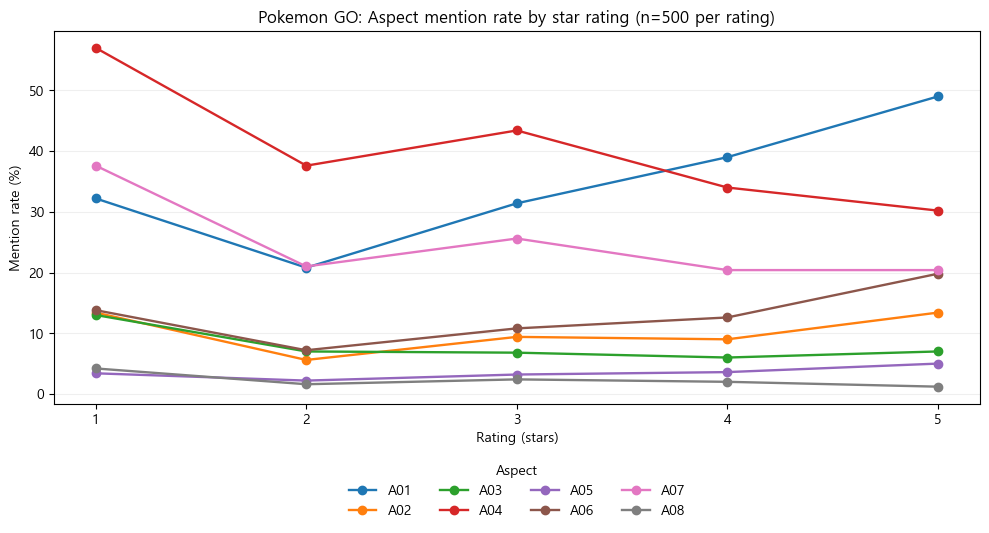

In [7]:
plt.rcParams['axes.unicode_minus']=False
# 한글 글꼴이 있는 환경에서는 자동 사용; 없으면 영어 코드 중심 표시
from matplotlib import font_manager
available={f.name for f in font_manager.fontManager.ttflist}
for candidate in ['Malgun Gothic','NanumGothic','AppleGothic','Noto Sans CJK KR']:
    if candidate in available:
        plt.rcParams['font.family']=candidate
        break
fig,ax=plt.subplots(figsize=(10,5.5))
for code in ASPECTS:
    sub=counts[counts['코드']==code].sort_values('별점')
    ax.plot(sub['별점'],sub['출현율(%)'],marker='o',label=code,linewidth=1.7)
ax.set(xlabel='Rating (stars)',ylabel='Mention rate (%)',title='Pokemon GO: Aspect mention rate by star rating (n=500 per rating)')
ax.set_xticks(RATINGS)
ax.grid(axis='y',alpha=.2)
ax.legend(title='Aspect',ncol=4,loc='upper center',bbox_to_anchor=(.5,-.13),frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR/'Figure_01_Mention_Rate_by_Rating.png',dpi=180,bbox_inches='tight')
plt.show()

## 7. 해석 보조 및 데이터 한계

- 유의한 χ²는 **관련성**을 보여주며 인과관계를 뜻하지 않습니다.
- 조정표준화잔차는 차이가 나타나는 별점을 탐색하는 **보조 지표**입니다. 여러 셀을 동시에 검토한다면 추가적인 다중비교 주의가 필요합니다.
- 별점별 표본을 동일한 크기로 추출하였으므로 결과를 전체 스토어 리뷰의 실제 별점 비중으로 해석하면 안 됩니다.
- 2,000건에 AI 예비 코딩이 포함되어 있다면 사람 A의 독립적인 코드 검증을 거친 500건에서 계산한 신뢰도만으로 2,000건 코딩 품질이 입증되지는 않습니다.

In [8]:
significant=summary[summary['FDR_유의여부']=='유의']
print(f'FDR q < {ALPHA} 평가속성: {len(significant)}/{len(ASPECTS)}개')
print('유의 속성:', ', '.join(significant['코드'].tolist()) if len(significant) else '없음')
print('기대빈도 5 미만 셀을 가진 속성:', summary.loc[summary['기대빈도5미만셀']>0,'코드'].tolist())
print('출력 디렉터리:',OUT_DIR.resolve())

FDR q < 0.05 평가속성: 7/8개
유의 속성: A01, A02, A03, A04, A06, A07, A08
기대빈도 5 미만 셀을 가진 속성: []
출력 디렉터리: D:\vscode_project\포켓몬고\PokemonGO_Stage2_Results
